# DuckDB Masterclass — Capítulo 02
## Transações ACID, concorrência, MVCC e WAL

**Edição para estudo autônomo e publicação no GitHub**  
**Exemplos:** operações e chamados técnicos em telecomunicações  
**Pré-requisitos:** SQL básico, Python e Jupyter Notebook

> **Roteiro:** ler a hipótese → executar cada célula na ordem → conferir as verificações → responder à autoavaliação. Este notebook preserva os experimentos realizados na mentoria e ajusta a preparação para execução reproduzível. Os resultados podem variar em detalhes (por exemplo, tamanho do WAL).

**Tempo sugerido:** 35–50 minutos. **Versão utilizada nos laboratórios originais:** DuckDB 2.0.0.

## 02.1 — Objetivos e diagnóstico inicial

Ao terminar, você deverá:

1. Diferenciar **Atomicidade**, **Consistência**, **Isolamento** e **Durabilidade**.
2. Executar `BEGIN`, `COMMIT` e `ROLLBACK` e verificar os resultados.
3. Observar isolamento de leitura e conflito de escrita com duas conexões.
4. Distinguir `COMMIT`, WAL e `CHECKPOINT`.

**Antes de começar:** se um erro ocorrer depois do primeiro `UPDATE` de uma transação com duas alterações, o que deve acontecer com a primeira alteração? Registre mentalmente sua hipótese.

## 02.2 — Conceitos essenciais

| ACID | Significado prático | Evidência neste capítulo |
|---|---|---|
| **A — Atomicidade** | Tudo é confirmado ou revertido | `ROLLBACK` restaura saldos |
| **C — Consistência** | Regras e restrições de integridade devem ser respeitadas | Conferência de saldos e regras; a conservação da soma vem da lógica dos `UPDATE` |
| **I — Isolamento** | Transações não devem expor alterações pendentes indevidamente | Leituras concorrentes via MVCC |
| **D — Durabilidade** | Alterações confirmadas persistem em armazenamento adequado | Reabertura de banco em arquivo; observação de WAL |

**Atenção:** `COMMIT` não garante, por si só, que a soma entre contas permaneça 200. Essa regra depende da operação de negócio (e, quando aplicável, de restrições definidas).

## 02.3 — Preparação reproduzível

Execute as células **em ordem, de cima para baixo**. Se `duckdb` não estiver disponível, instale-o no ambiente do kernel (`pip install duckdb pandas`) e reinicie o kernel. A instalação não ocorre automaticamente neste notebook.

Os laboratórios 02.4 e 02.5 usam um banco independente em memória; os seguintes usam arquivos isolados. **Não execute `Run All` repetidamente sem reiniciar o kernel** se quiser comparar as saídas do primeiro percurso.

In [13]:
import duckdb
import tempfile
from pathlib import Path
from uuid import uuid4
from IPython.display import display

print('DuckDB:', duckdb.__version__)
con = duckdb.connect(':memory:')

DuckDB: 2.0.0


## 02.4 — Laboratório guiado: Atomicidade e `ROLLBACK`

**Cenário:** transferir 30 unidades do saldo 1 para o saldo 2. Vamos executar os dois `UPDATE` e desistir da operação.

**Hipótese:** depois de `ROLLBACK`, os dois saldos permanecem 100.

In [14]:
con.execute("CREATE TABLE saldos (id INTEGER PRIMARY KEY, saldo INTEGER)")
con.execute("INSERT INTO saldos VALUES (1,100),(2,100)")

con.execute('BEGIN TRANSACTION')
con.execute('UPDATE saldos SET saldo = saldo - 30 WHERE id = 1')
con.execute('UPDATE saldos SET saldo = saldo + 30 WHERE id = 2')
con.execute('ROLLBACK')

saldos_rollback = con.execute('SELECT * FROM saldos ORDER BY id').df()
display(saldos_rollback)
assert saldos_rollback['saldo'].tolist() == [100, 100]
print('ROLLBACK validado: saldos restaurados.')

,id,saldo
0,1,100
1,2,100


ROLLBACK validado: saldos restaurados.


**Interpretação:** as duas alterações foram desfeitas, comprovando a reversão da transação. Não testamos concorrência nem durabilidade neste passo.

## 02.5 — Experimentação controlada: `COMMIT`

Vamos repetir a transferência, agora confirmando-a. **Hipótese:** saldos finais 70 e 130.

In [15]:
con.execute('BEGIN TRANSACTION')
con.execute('UPDATE saldos SET saldo = saldo - 30 WHERE id = 1')
con.execute('UPDATE saldos SET saldo = saldo + 30 WHERE id = 2')
con.execute('COMMIT')

saldos_commit = con.execute('SELECT * FROM saldos ORDER BY id').df()
display(saldos_commit)
assert saldos_commit['saldo'].tolist() == [70, 130]
assert saldos_commit['saldo'].sum() == 200
print('COMMIT validado: transferência confirmada.')

,id,saldo
0,1,70
1,2,130


COMMIT validado: transferência confirmada.


### 🧠 O que ocorre ao tentar `ROLLBACK` após `COMMIT`?

Uma transação já encerrada não pode ser desfeita com um novo `ROLLBACK`. O erro abaixo **é esperado**; não significa que o laboratório falhou.

In [16]:
try:
    con.execute('ROLLBACK')
except duckdb.TransactionException as erro:
    print('Erro esperado:', erro)

assert con.execute('SELECT saldo FROM saldos WHERE id = 1').fetchone()[0] == 70

Erro esperado: TransactionContext Error: cannot rollback - no transaction is active


**Aprendizado:** `ROLLBACK` desfaz uma transação ainda aberta; `COMMIT` a encerra e confirma. A conservação do total de 200 decorreu da lógica dos dois `UPDATE`.

## 02.6 — Desafio profissional: concorrência e MVCC

**Cenário:** a rotina A altera o chamado 101 de `ABERTO` para `EM_REPARO`; a rotina B consulta e tenta marcar o mesmo chamado como `CANCELADO`.

**Objetivo:** observar o isolamento de leitura e a detecção de um conflito de escrita, sem confundir os dois mecanismos.

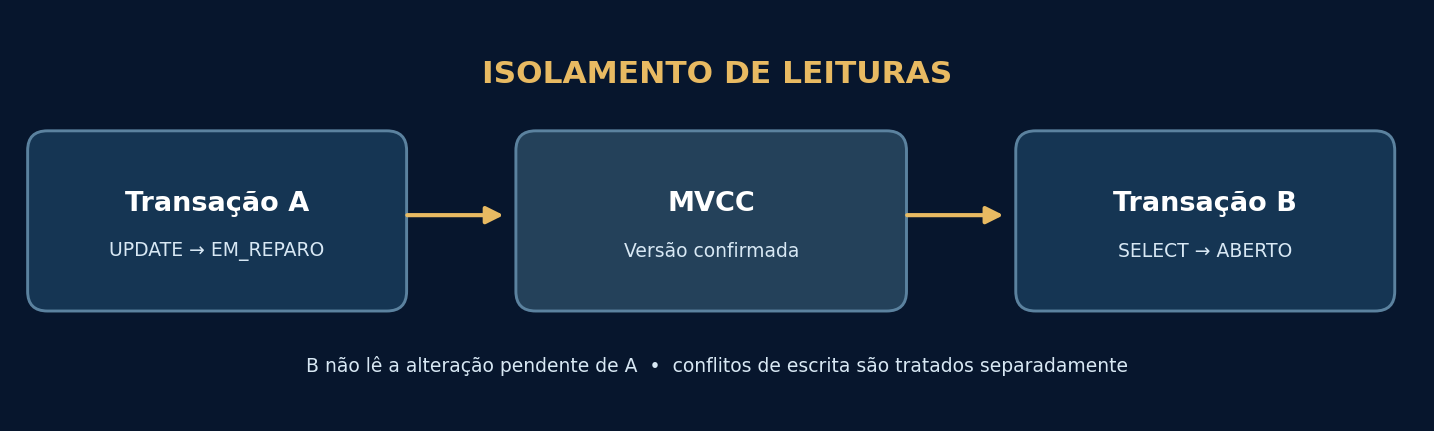

### 🔬 Laboratório 02.6.1 — Preparando duas conexões

Usaremos um **arquivo temporário** compartilhado por duas conexões **no mesmo processo Python**. Duas conexões independentes abertas com `:memory:` não representariam o mesmo banco.

In [17]:
pasta_concorrencia = tempfile.TemporaryDirectory()
caminho_concorrencia = str(Path(pasta_concorrencia.name) / 'concorrencia.duckdb')
con_a = duckdb.connect(caminho_concorrencia)
con_b = duckdb.connect(caminho_concorrencia)
con_a.execute('CREATE TABLE chamados (id INTEGER PRIMARY KEY, status VARCHAR)')
con_a.execute("INSERT INTO chamados VALUES (101, 'ABERTO'), (102, 'ABERTO')")
print('Conexões A e B preparadas.')

Conexões A e B preparadas.


### 🔬 Laboratório 02.6.2 — Isolamento de leitura

**Pergunta:** antes do `COMMIT` de A, qual status B visualizará?

In [18]:
con_a.execute('BEGIN TRANSACTION')
con_b.execute('BEGIN TRANSACTION')
con_a.execute("UPDATE chamados SET status = 'EM_REPARO' WHERE id = 101")
status_a = con_a.execute('SELECT status FROM chamados WHERE id = 101').fetchone()[0]
status_b = con_b.execute('SELECT status FROM chamados WHERE id = 101').fetchone()[0]
print('Transação A:', status_a)
print('Transação B:', status_b)
assert (status_a, status_b) == ('EM_REPARO', 'ABERTO')

Transação A: EM_REPARO
Transação B: ABERTO


**Interpretação:** A lê sua alteração não confirmada; B ainda consulta `ABERTO`. MVCC permite leituras isoladas sem exigir que B espere o `COMMIT` para ler.

### 🔬 Laboratório 02.6.3 — Conflito de escrita

**Pergunta:** B pode atualizar a **mesma linha** enquanto a transação A ainda está aberta?

In [19]:
conflito_detectado = False
try:
    con_b.execute("UPDATE chamados SET status = 'CANCELADO' WHERE id = 101")
except duckdb.TransactionException as erro:
    conflito_detectado = True
    print('Conflito detectado:', erro)
assert conflito_detectado, 'Esperávamos conflito na atualização da mesma linha.'

Conflito detectado: TransactionContext Error: Conflict on update!


### 🔬 Laboratório 02.6.4 — Resolução

Vamos reverter B, confirmar A e verificar o estado final. Em uma aplicação real, uma nova tentativa de B deve reler o status e reavaliar a regra de negócio.

In [20]:
con_b.execute('ROLLBACK')
con_a.execute('COMMIT')
resultado_chamados = con_a.execute('SELECT * FROM chamados ORDER BY id').df()
display(resultado_chamados)
assert resultado_chamados['status'].tolist() == ['EM_REPARO','ABERTO']
con_b.close()
con_a.close()
print('Conflito tratado; conexões encerradas.')

,id,status
0,101,EM_REPARO
1,102,ABERTO


Conflito tratado; conexões encerradas.


### 🧠 Conclusão — MVCC e concorrência

- **Isolamento:** B não leu a alteração pendente de A.
- **Escrita:** B recebeu `Conflict on update!` ao disputar a mesma linha.
- **Tratamento:** B foi revertida; A foi confirmada.

**Limite:** este experimento não representa duas aplicações em processos independentes escrevendo livremente no mesmo arquivo. Em modo embutido, o DuckDB tem regras específicas de acesso multiprocesso; consulte a documentação correspondente à sua versão.

## 02.7 — Durabilidade e WAL (*Write-Ahead Log*)

**Cenário:** um reparo concluído precisa continuar registrado após encerrar o banco.

- `COMMIT` confirma a transação.
- **WAL** registra alterações para auxiliar a recuperação.
- `CHECKPOINT` incorpora o WAL ao arquivo principal.

**Pergunta central:** o que acontece após fechar, reabrir e executar um `CHECKPOINT`?

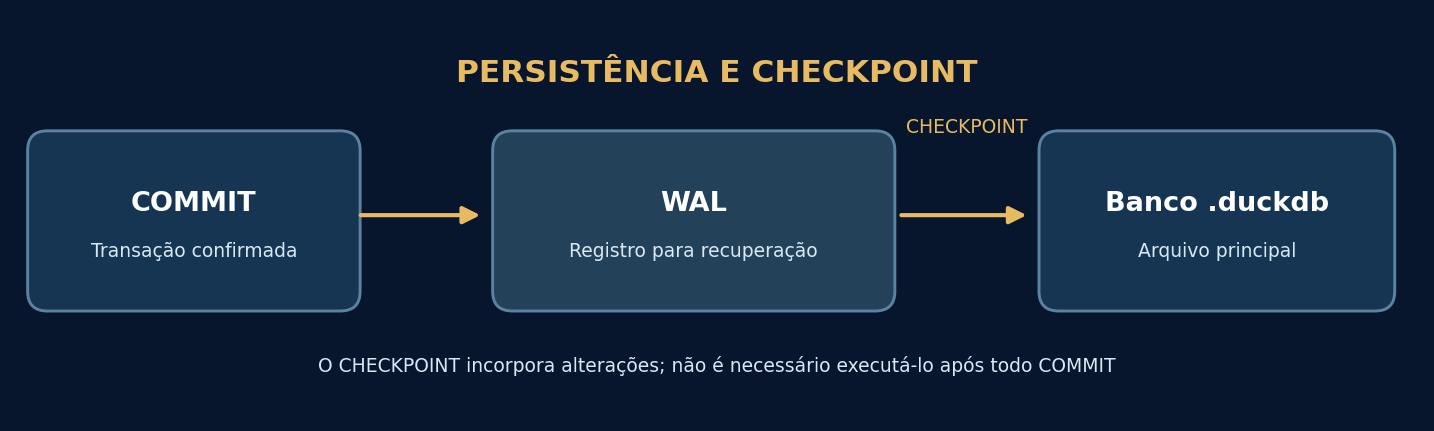

### 🔬 Laboratório 02.7.1 — Confirmando uma transação

**Objetivo:** inserir o chamado 101 com status `CONCLUIDO` e fechar a conexão normalmente.

In [21]:
pasta_durabilidade = tempfile.TemporaryDirectory()
banco_durabilidade = str(Path(pasta_durabilidade.name) / 'durabilidade.duckdb')
db = duckdb.connect(banco_durabilidade)
db.execute('CREATE TABLE reparos (id INTEGER PRIMARY KEY, status VARCHAR)')
db.execute('BEGIN TRANSACTION')
db.execute("INSERT INTO reparos VALUES (101, 'CONCLUIDO')")
db.execute('COMMIT')
db.close()
print('Transação confirmada e conexão encerrada.')

Transação confirmada e conexão encerrada.


### 🔬 Laboratório 02.7.2 — Reabrindo o banco

**Hipótese:** o registro continuará acessível após um **encerramento normal**. Isso não simula queda de energia.

In [22]:
db_reaberto = duckdb.connect(banco_durabilidade)
resultado_durabilidade = db_reaberto.execute('SELECT * FROM reparos ORDER BY id').df()
display(resultado_durabilidade)
assert resultado_durabilidade.loc[0, 'status'] == 'CONCLUIDO'
print('Persistência confirmada após reabertura!')
db_reaberto.close()

,id,status
0,101,CONCLUIDO


Persistência confirmada após reabertura!


### 🔬 Laboratório 02.7.3 — Observando o WAL

Criaremos um banco **separado** na pasta `dados/`, com nome único para evitar conflito com execuções anteriores. Para preservar a privacidade na publicação, mostramos somente o **caminho relativo** (`dados/nome_do_banco.duckdb`), não o caminho completo do computador. O arquivo `.wal` é gerenciado internamente pelo DuckDB: sua presença/tamanho variam com a versão e os checkpoints automáticos.

In [23]:
raiz_projeto = Path.cwd()
pasta_dados = raiz_projeto / 'dados'
pasta_dados.mkdir(parents=True, exist_ok=True)
caminho_wal = pasta_dados / f'wal_lab_{uuid4().hex[:8]}.duckdb'
con_wal = duckdb.connect(str(caminho_wal))
con_wal.execute('CREATE TABLE eventos (id INTEGER PRIMARY KEY, descricao VARCHAR)')
con_wal.execute('BEGIN TRANSACTION')
con_wal.execute("INSERT INTO eventos VALUES (1, 'Reparo concluido')")
con_wal.execute('COMMIT')
arquivo_wal = Path(str(caminho_wal) + '.wal')
print('Banco:', caminho_wal.relative_to(raiz_projeto).as_posix())
print('Arquivo principal:', caminho_wal.exists())
print('WAL presente:', arquivo_wal.exists())
if arquivo_wal.exists():
    print('Tamanho do WAL (bytes):', arquivo_wal.stat().st_size)

Banco: dados/wal_lab_267e884c.duckdb
Arquivo principal: True
WAL presente: True
Tamanho do WAL (bytes): 416


### 🔬 Laboratório 02.7.4 — Executando `CHECKPOINT`

**Hipótese:** após o checkpoint, o WAL poderá desaparecer ou esvaziar; os dados devem continuar acessíveis.

In [24]:
print('WAL antes:', arquivo_wal.exists())
con_wal.execute('CHECKPOINT')
print('WAL depois:', arquivo_wal.exists())
if arquivo_wal.exists():
    print('Tamanho depois (bytes):', arquivo_wal.stat().st_size)
resultado_wal = con_wal.execute('SELECT * FROM eventos').df()
display(resultado_wal)
assert resultado_wal.loc[0, 'descricao'] == 'Reparo concluido'
con_wal.close()

WAL antes: True
WAL depois: False


,id,descricao
0,1,Reparo concluido


### 🧠 Conclusão — Durabilidade e WAL

- **Persistência:** os dados sobreviveram ao fechamento e à reabertura normal do banco.
- **WAL:** observamos um arquivo de log após `COMMIT` nos experimentos da mentoria (402 bytes naquela execução).
- **CHECKPOINT:** naquela execução, o WAL desapareceu e os dados permaneceram acessíveis.

**Limite:** não simulamos uma falha inesperada de processo, sistema ou disco. `CHECKPOINT` não precisa ser acionado manualmente após cada `COMMIT`.

## 02.8 — Autoavaliação e visão de especialista

**Antes de ver as respostas, explique cada situação em uma frase e cite uma verificação prática.**

1. Uma transferência falha depois do primeiro `UPDATE`. Qual propriedade ACID e qual comando são relevantes?
2. A altera um chamado sem `COMMIT`; B consulta o mesmo registro. O que B visualiza e por quê?
3. Duas transações atualizam a mesma linha. Como o DuckDB reage e qual é o tratamento apropriado?
4. Depois de `COMMIT`, mas antes de `CHECKPOINT`, a transação já está confirmada? Qual é o papel do WAL?
5. Para cada situação anterior, que teste SQL ou Python permitiria verificar a conclusão?

### Gabarito comentado — consulte após tentar

1. **Atomicidade + `ROLLBACK`:** validar o estado antes/depois e verificar que nenhuma atualização parcial ficou confirmada.
2. **Versão anterior confirmada:** o MVCC isola a leitura de alterações pendentes; B não precisa esperar A para consultar.
3. **Conflito de escrita:** a segunda atualização pode gerar `Conflict on update!`; reverter a transação com erro, reler o estado em uma nova transação e avaliar uma nova tentativa.
4. **Sim:** `COMMIT` confirma. O WAL participa da recuperação; `CHECKPOINT` incorpora as alterações ao arquivo principal.
5. **Evidências:** `SELECT`, `assert`, comparação de estados, tratamento da exceção e reabertura do arquivo para persistência normal.

**Conclusão da mentoria:** 5 questões concluídas; média de 9,3/10. **Meta para o autoestudo:** não apenas acertar os nomes, mas explicar como cada hipótese é comprovada.

## 02.9 — Leituras oficiais e próximos passos

- [DuckDB — Transações](https://duckdb.org/docs/stable/sql/statements/transactions)
- [DuckDB — Concorrência](https://duckdb.org/docs/stable/connect/concurrency)
- [DuckDB — CHECKPOINT](https://duckdb.org/docs/stable/sql/statements/checkpoint)
- [DuckDB — Python Client](https://duckdb.org/docs/stable/clients/python/overview)

### Publicando este notebook no GitHub

1. Confira se o kernel contém `duckdb` e execute as células **na ordem** (`Kernel → Restart & Run All`).
2. Antes de publicar, confirme que não há caminhos privados (ex.: `C:\Users\...`), nomes de usuário, credenciais ou dados reais de clientes. Evite `Path.resolve()` e `Path.cwd()` em comandos `print` destinados à publicação; prefira caminhos relativos.
3. Adicione ao `.gitignore` as linhas `dados/`, `*.duckdb`, `*.duckdb.wal` e `.ipynb_checkpoints/`.
4. Publique o arquivo `.ipynb`: as duas ilustrações estão **incorporadas ao notebook**, sem depender de URLs externas.

**Nota de versão:** as saídas documentadas nos laboratórios originais foram observadas em DuckDB 2.0.0. Versões posteriores podem mudar mensagens de erro, nomes de parâmetros e detalhes internos do WAL.